# BÀI THỰC HÀNH 3.2: K-MEANS IMAGE SEGMENTATION
## NOTEBOOK 01: NẠP ẢNH, KHÔNG GIAN MÀU VÀ TIỀN XỬ LÝ (TASK 1 & TASK 2)

Mục tiêu bài thực hành:
1. **Task 1: Load the Image & Convert Color Space**: Đọc ảnh đầu vào bằng OpenCV / Pillow, xác thực dữ liệu và chuyển đổi sang các hệ màu RGB, HSV, LAB.
2. **Task 2: Preprocess the Image**: Thu nhỏ kích thước ảnh (cạnh dài $\le 256$ pixel) để tối ưu tính toán nhưng giữ nguyên tỷ lệ khung hình, làm phẳng ma trận thành mảng 2 chiều $(N, 3)$ với mỗi điểm ảnh là một vector màu.

### 1. Cấu hình hệ thống và nạp các module dự án

In [1]:
import sys
from pathlib import Path

# Thiết lập đường dẫn thư mục gốc để nạp module src
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.config import DEFAULT_IMAGE_PATH, TARGET_SIZE, FIGURES_DIR
from src.data.loader import load_image, validate_image
from src.data.preprocessing import convert_color_space, resize_image, flatten_pixels
from src.evaluation.visualization import plot_color_space_comparison

print(f"Thư mục dự án: {PROJECT_ROOT}")
print(f"File ảnh mặc định: {DEFAULT_IMAGE_PATH}")

Thư mục dự án: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION
File ảnh mặc định: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\data\raw\image-liquid.jpg


### 2. Nạp ảnh gốc và kiểm định tính toàn vẹn (Task 1)
Đọc ảnh bằng OpenCV (`cv2.imread` và chuyển từ BGR sang RGB) hoặc fallback sang Pillow nếu cần.

In [2]:
# Đọc ảnh và trích xuất metadata chi tiết
img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)

print("=== THÔNG TIN SIÊU DỮ LIỆU (METADATA) CỦA ẢNH ===")
for k, v in metadata.items():
    print(f"{k:20s}: {v}")

# Kiểm định hợp lệ
is_valid = validate_image(img_rgb)
print(f"\nTrạng thái kiểm định ảnh hợp lệ: {is_valid}")

2026-11-14 11:08:07 [INFO] DataLoader — Đọc ảnh bằng OpenCV: image-liquid.jpg
2026-11-14 11:08:07 [INFO] DataLoader — Ảnh đã nạp — image-liquid.jpg | 3264×3264×3 | 10,653,696 pixels | 2095.2 KB
=== THÔNG TIN SIÊU DỮ LIỆU (METADATA) CỦA ẢNH ===
filename            : image-liquid.jpg
filepath            : E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\data\raw\image-liquid.jpg
original_height     : 3264
original_width      : 3264
channels            : 3
original_shape      : (3264, 3264, 3)
total_pixels        : 10653696
dtype               : uint8
file_size_bytes     : 2145517
color_format        : OpenCV (BGR→RGB)

Trạng thái kiểm định ảnh hợp lệ: True


### 3. Khảo sát và chuyển đổi các không gian màu (RGB, HSV, LAB)
Khảo sát các biểu diễn màu khác nhau để hiểu đặc tính quang học của từng hệ màu trước khi phân cụm.

2026-11-14 11:08:15 [INFO] Preprocessing — Chuyển không gian màu (OpenCV): RGB -> HSV
2026-11-14 11:08:15 [INFO] Preprocessing — Chuyển không gian màu (OpenCV): RGB -> LAB
2026-11-14 11:08:20 [INFO] Visualization — Đã lưu color space comparison: E:\mayhc\Lab_3.2_ADDITIONAL_K-MEANS_IMAGE_SEGMENTATION\results\figures\color_spaces_comparison_nb01.png


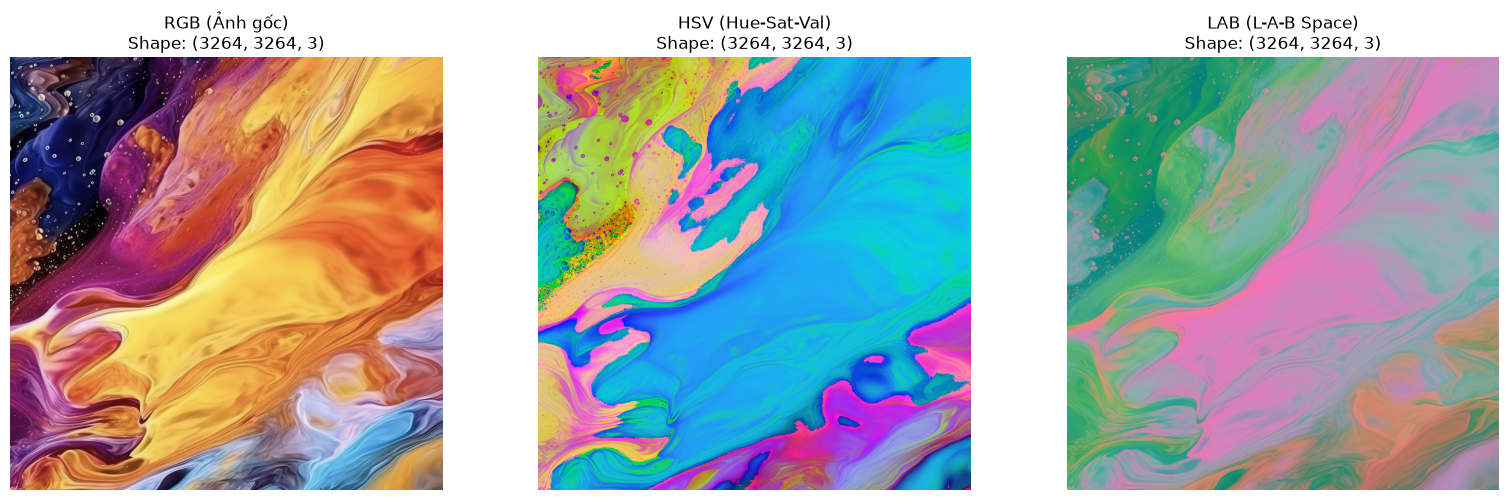

In [3]:
# Chuyển đổi không gian màu sang HSV và LAB
img_hsv = convert_color_space(img_rgb, source_space="RGB", target_space="HSV")
img_lab = convert_color_space(img_rgb, source_space="RGB", target_space="LAB")

# Trực quan hóa so sánh trực tiếp
plot_color_space_comparison(
    img_rgb=img_rgb,
    img_hsv=img_hsv,
    img_lab=img_lab,
    save_path=FIGURES_DIR / "color_spaces_comparison_nb01.png"
)

# Hiển thị trực tiếp trong notebook
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(img_rgb)
axes[0].set_title(f"RGB (Ảnh gốc)\nShape: {img_rgb.shape}")
axes[0].axis("off")

# Chuẩn hóa hiển thị HSV và LAB
hsv_disp = img_hsv.astype(np.float32)
hsv_disp[:, :, 0] /= 180.0
hsv_disp[:, :, 1] /= 255.0
hsv_disp[:, :, 2] /= 255.0
axes[1].imshow(np.clip(hsv_disp, 0, 1))
axes[1].set_title(f"HSV (Hue-Sat-Val)\nShape: {img_hsv.shape}")
axes[1].axis("off")

lab_disp = (img_lab.astype(np.float32) - img_lab.min()) / (img_lab.max() - img_lab.min() + 1e-8)
axes[2].imshow(np.clip(lab_disp, 0, 1))
axes[2].set_title(f"LAB (L-A-B Space)\nShape: {img_lab.shape}")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### 4. Resize ảnh theo tỷ lệ khung hình và Flatten ma trận điểm ảnh (Task 2)
Giảm kích thước cạnh dài về $256$ pixel để thuật toán K-Means chạy nhanh, sau đó chuyển ảnh 3D $(H, W, 3)$ thành ma trận 2D $(N, 3)$.

In [4]:
# 1. Resize ảnh (giữ nguyên tỷ lệ khung hình)
img_resized, (new_h, new_w) = resize_image(
    img_rgb,
    target_size=TARGET_SIZE,
    keep_aspect_ratio=True
)

print(f"Kích thước ảnh gốc: {img_rgb.shape[:2]} ({metadata['total_pixels']:,} điểm ảnh)")
print(f"Kích thước ảnh sau resize: ({new_h}, {new_w}) ({new_h * new_w:,} điểm ảnh)")
print(f"Tỷ lệ nén số lượng pixel: {metadata['total_pixels'] / (new_h * new_w):.2f}x lần")

# 2. Flatten ma trận điểm ảnh thành 2D
pixel_matrix = flatten_pixels(img_resized, as_float=True)

print(f"\nMa trận điểm ảnh 2D:\n- Shape: {pixel_matrix.shape}\n- Dtype: {pixel_matrix.dtype}")
print(f"- Giá trị pixel Min: {pixel_matrix.min()}, Max: {pixel_matrix.max()}")
print(f"- 5 điểm ảnh đầu tiên (RGB):\n{pixel_matrix[:5]}")

2026-11-14 11:08:30 [INFO] Preprocessing — Resize ảnh: (3264x3264) -> (256x256) | scale=0.078
Kích thước ảnh gốc: (3264, 3264) (10,653,696 điểm ảnh)
Kích thước ảnh sau resize: (256, 256) (65,536 điểm ảnh)
Tỷ lệ nén số lượng pixel: 162.56x lần
2026-11-14 11:08:30 [INFO] Preprocessing — Flatten pixels: (256x256x3) -> (65536, 3) | dtype=float32

Ma trận điểm ảnh 2D:
- Shape: (65536, 3)
- Dtype: float32
- Giá trị pixel Min: 2.0, Max: 253.0
- 5 điểm ảnh đầu tiên (RGB):
[[ 25.  37.  89.]
 [ 37.  47. 101.]
 [ 47.  56. 108.]
 [ 72.  78. 126.]
 [ 81.  86. 134.]]


### 5. Kết luận Task 1 & Task 2
- Ảnh đầu vào đã được nạp thành công ở hệ màu RGB tiêu chuẩn.
- Quá trình resize bảo toàn tỷ lệ khung hình giúp giảm khối lượng tính toán hơn hàng chục lần mà không làm biến dạng hình học.
- Ma trận điểm ảnh 2D `(N, 3)` kiểu `float32` trong khoảng $[0.0, 255.0]$ đã sẵn sàng cho bước phân cụm K-Means ở Notebook 02.